In [1]:
import pandas as pd
from load import MergedExposureDataset, MonitorsDataset
import matplotlib.pyplot as plt
import geopandas as gpd
import textwrap
from config import *

sdf = gpd.read_file(STATESHAPEFILE_PATH)
sdf = sdf[sdf['STUSPS'].isin(['AZ', 'CA', 'CO', 'ID', 'MT', 'NV', 'NM', 'OR', 'UT', 'WA','WY'])]

INFO:load:Loading MonitorsDataset from path ../coexposure/data/annual_conc_by_monitor_2023.csv
INFO:load:Monitors CRS: ['NAD83' 'WGS84']
INFO:load:Loading ShapefileDataset from path ../coexposure/data/WesternUSCensusTract/CensusTract2020_WesternUS.shp
INFO:load:Shapefile CRS: PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]]


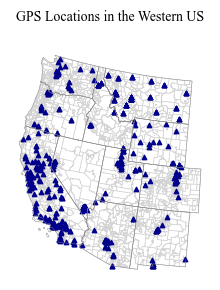

In [2]:
MonitorsDataset().plotMonitors()

In [2]:
df = MergedExposureDataset(reload=True).getMergedExposure()

INFO:load:Loading SmokePMDataset from path smoke_pm/area_weighted_smoke_pm_corr.parquet


Reloading data and ignoring cache for cache/merged_df.pkl.


INFO:load:Data loaded from cache.
INFO:load:Data summary:        avg_yrly_smoke_pm_gt_5  avg_yrly_smoke_pm
count            18108.000000       18108.000000
mean                 8.954536           0.535156
std                  5.064510           0.378835
min                  2.066667           0.105642
25%                  5.533333           0.275517
50%                  7.466667           0.402458
75%                 10.933333           0.710694
max                 37.133333           3.180479
INFO:load:Loading TotalPM25Dataset from path ../coexposure/outputs/total_total_pm25_pollution.parquet


Loading cached data from cache/smoke_pm_df.pkl


INFO:load:Data loaded from cache.
INFO:load:Data summary:        avg_yrly_pm25_gt_5  avg_yrly_pm25
count        18010.000000   18010.000000
mean           274.178223       8.961714
std             82.111820       3.122284
min             26.333333       2.187771
25%            221.733333       6.698694
50%            301.933333       8.336958
75%            345.200000      11.012399
max            359.666667      20.074779
INFO:load:Loading UrbanRuralDataset from path ../coexposure/data/joan_ruca/ruca2020.csv


Loading cached data from cache/total_pm25_df.pkl


... (2 outputs left out)

INFO:load:Shapefile CRS: PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]]
INFO:load:Data loaded from cache.
INFO:load:Data summary:          POPULATION          SQMI
count  18107.000000  18107.000000
mean    4215.609819     65.468363
std     1683.811154    368.600971
min        0.000000      0.010000
25%     3074.500000      0.510000
50%     4076.000000      1.010

Loading cached data from cache/shapefile_df.pkl


INFO:load:Monitors CRS: ['NAD83' 'WGS84']
INFO:load:Loading ShapefileDataset from path ../coexposure/data/WesternUSCensusTract/CensusTract2020_WesternUS.shp
INFO:load:Shapefile CRS: PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]]
INFO:load:Data loaded from cache.
INFO:load:Data summary:            distance  monitor_count
count  18107.000000   18107.000000
mean   

Loading cached data from cache/monitors_df.pkl


In [3]:
gdf = gpd.GeoDataFrame(df, geometry=df.geometry, crs="ESRI:102003")

In [4]:
sdf = sdf.to_crs(gdf.crs)

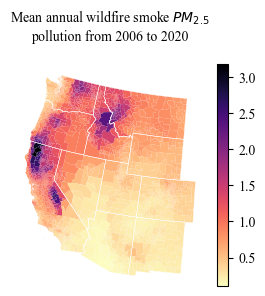

In [5]:
norm = None
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
x = "avg_yrly_smoke_pm"
gdf.plot(
    column=x, 
    # vmax=5000,
    # vmin=500,
    ax=ax, 
    legend=True, 
    linewidth=0, 
    cmap="magma_r", 
    missing_kwds={"color": "lightgrey"}, norm = norm
    )
sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
wrapped_title = textwrap.fill(r"Mean annual wildfire smoke $PM_{2.5}$ pollution from 2006 to 2020", 40) # " "
ax.set_title(wrapped_title, fontsize=10)
ax.set_axis_off()

plt.tight_layout()
plt.savefig("figures/centract_hotspots_wc_241028.png", dpi=300, bbox_inches='tight')
plt.show()

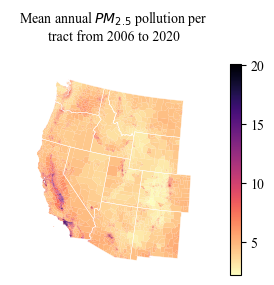

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(3, 3))

# vmax = data[x].max()
# vmin = data[x].min()
# vmax = 0.7 * vmax
cmap = "magma_r"
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
# sm.set_array([])
x = "avg_yrly_pm25"
gdf.plot(
    column=x, 
    ax=ax, 
    legend=True, 
    #aspect='equal',
    # vmax=5000,
    # vmin=500,
    linewidth=0, 
    cmap=cmap, 
    missing_kwds={"color": "lightgrey"},
    )
sdf.boundary.plot(ax=ax, linewidth=0.3, color='white')

#title_text = "Total days of air pollution exposure ("+ titles[x]+ ") from 2006 to 2020"
title_text = r"Mean annual $PM_{2.5}$ pollution per tract from 2006 to 2020"
wrapped_title = textwrap.fill(title_text, 40)
ax.set_title(wrapped_title, fontsize=10)
ax.set_axis_off()
plt.axis('equal')
plt.tight_layout()
plt.savefig("figures/centract_hotspots_wc_mean_pm25_air"+x+".png", dpi=300, bbox_inches='tight')
plt.show()

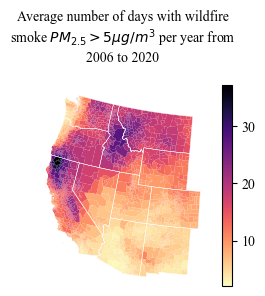

In [8]:
norm = None
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
x = "avg_yrly_smoke_pm_gt_5"
gdf.plot(
    column=x, 
    # vmax=5000,
    # vmin=500,
    ax=ax, 
    legend=True, 
    linewidth=0, 
    cmap="magma_r", 
    missing_kwds={"color": "lightgrey"}, norm = norm
    )
sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
wrapped_title = textwrap.fill(r"Average number of days with wildfire smoke $PM_{2.5}>5μg/m^3$ per year from 2006 to 2020", 40) # " "
ax.set_title(wrapped_title, fontsize=10)
ax.set_axis_off()

plt.tight_layout()
plt.savefig("figures/avg_yrly_smoke_pm_gt_5.png", dpi=300, bbox_inches='tight')
plt.show()

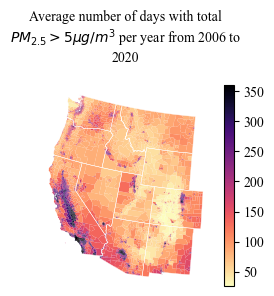

In [9]:
norm = None
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
x = "avg_yrly_pm25_gt_5"
gdf.plot(
    column=x, 
    # vmax=5000,
    # vmin=500,
    ax=ax, 
    legend=True, 
    linewidth=0, 
    cmap="magma_r", 
    missing_kwds={"color": "lightgrey"}, norm = norm
    )
sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
wrapped_title = textwrap.fill(r"Average number of days with total $PM_{2.5}>5μg/m^3$ per year from 2006 to 2020", 40) # " "
ax.set_title(wrapped_title, fontsize=10)
ax.set_axis_off()

plt.tight_layout()
plt.savefig("figures/avg_yrly_pm25_gt_5.png", dpi=300, bbox_inches='tight')
plt.show()

In [11]:
gdf.columns

Index(['avg_yrly_smoke_pm_gt_5', 'avg_yrly_smoke_pm', 'avg_yrly_pm25_gt_5',
       'avg_yrly_pm25', 'classification', 'nearest_monitor', 'distance',
       'monitor_count', 'STATE_ABBR', 'POPULATION', 'SQMI', 'geometry', 'SQKM',
       'monitors_sqkm', 'popw_avg_yrly_smoke_pm'],
      dtype='object')

In [11]:
gdf.head()

,avg_yrly_smoke_pm_gt_5,avg_yrly_smoke_pm,avg_yrly_pm25_gt_5,avg_yrly_pm25,classification,nearest_monitor,distance,monitor_count,STATE_ABBR,POPULATION,SQMI,geometry,SQKM,monitors_sqkm,popw_avg_yrly_smoke_pm
location_label,,,,,,,,,,,,,,,
04001942600,4.533333,0.213761,105.733333,4.384537,Rural,978.0,102.621138,0.0,AZ,1549.0,589.09,"POLYGON ((-1218270.401 32832.246, -1211358.143...",1525.737209,0.0,0.000004
04001942700,4.666667,0.207732,74.666667,3.769251,Rural,978.0,97.191234,0.0,AZ,4491.0,1155.35,"POLYGON ((-1152995.229 23611.170, -1151650.010...",2992.344946,0.0,0.000012
04001944000,4.733333,0.211045,57.400000,3.467366,Rural,978.0,27.593764,0.0,AZ,5348.0,305.81,"POLYGON ((-1163367.996 -71037.222, -1163356.94...",792.044842,0.0,0.000015
04001944100,4.066667,0.192150,65.866667,3.543383,Rural,978.0,57.403297,0.0,AZ,5495.0,708.25,"POLYGON ((-1174876.260 -9365.197, -1174863.596...",1834.360417,0.0,0.000014
04001944201,3.666667,0.177660,98.200000,4.296198,Rural,978.0,39.335051,0.0,AZ,4021.0,193.93,"POLYGON ((-1210854.946 -45587.815, -1210757.05...",502.276761,0.0,0.000009


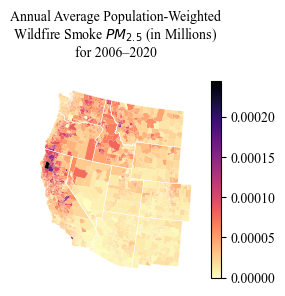

In [12]:
norm = None
fig, ax = plt.subplots(1, 1, figsize=(3, 3))

#gdf["wg_exp"] = gdf["popw_avg_yrly_smoke_pm"] * gdf["POPULATION"]
x = "popw_avg_yrly_smoke_pm"
gdf.plot(
    column=x, 
    ax=ax,
    legend=True, 
    linewidth=0, 
    cmap="magma_r", 
    missing_kwds={"color": "lightgrey"}, norm = norm
    )
sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
wrapped_title = textwrap.fill(
    r"Annual Average Population-Weighted Wildfire Smoke $PM_{2.5}$ (in Millions) for 2006–2020", 40)
ax.set_title(wrapped_title, fontsize=10)
ax.set_axis_off()

plt.tight_layout()
plt.savefig("figures/wg_exp.png", dpi=300, bbox_inches='tight')
plt.show()

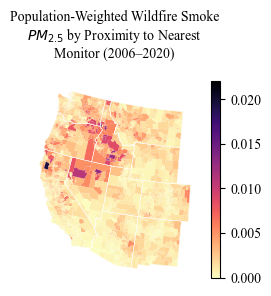

In [13]:
norm = None
fig, ax = plt.subplots(1, 1, figsize=(3, 3))

gdf["wg_exp_d"] = gdf["popw_avg_yrly_smoke_pm"] * gdf["distance"]
x = "wg_exp_d"
gdf.plot(
    column=x, 
    ax=ax,
    legend=True, 
    linewidth=0, 
    cmap="magma_r", 
    missing_kwds={"color": "lightgrey"}, norm = norm
    )
sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
wrapped_title = textwrap.fill(r"Population-Weighted Wildfire Smoke $PM_{2.5}$ by Proximity to Nearest Monitor (2006–2020)", 40) # " "
ax.set_title(wrapped_title, fontsize=10)
ax.set_axis_off()

plt.tight_layout()
plt.savefig("figures/wg_exp_d.png", dpi=300, bbox_inches='tight')
plt.show()

In [12]:
gdf.sort_values("wg_exp_d", ascending=False)[["classification","STATE_ABBR","POPULATION","wg_exp_d"]].head(10)

,classification,STATE_ABBR,POPULATION,wg_exp_d
location_label,,,,
16083000701,Urban,ID,11083.0,21994.816088
06105000500,Rural,CA,7007.0,19499.258416
16013960201,Urban,ID,6226.0,15759.672018
16069960700,Urban,ID,5776.0,14447.330788
16083000200,Urban,ID,7519.0,14416.574845
16083001301,Urban,ID,7292.0,14104.813231
16049960202,Rural,ID,4724.0,14069.561216
32007950701,Urban,NV,6886.0,13755.537393
16083000800,Urban,ID,6433.0,13343.861304
